## General

In [14]:
from collections import defaultdict
import json
import math
import pandas as pd

# Load data
with open('finalstep_stats_3.json') as f:
    data = json.load(f)
with open('finalrandla_stats_3.json') as f2:
    data2 = json.load(f2)
with open('finalmean_stats_3.json') as f3:
    data3 = json.load(f3)
with open('finalmax_stats_3.json') as f4:
    data4 = json.load(f4)
with open('finalrandom_1.json') as f5:
    data5 = json.load(f5)
with open('finalcombine_stats_3.json') as f6:
    data6 = json.load(f6)


def euclidean(p1, p2):
    """Simple 2D Euclidean distance"""
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)


# -------------------------------------------------
# Environment mapping + snapping
# -------------------------------------------------
env_map = {
    ((-30, 7), (-22, 17)): "normal",
    ((-30, -20), (-22, -6)): "uneven",
    ((-31, -44), (-20, -37)): "mutlti ramp",
    ((-55, 5), (-41, 5)): "two_height_ramp",
    ((-33, 40), (-20, 40)): "ramp_obstacle",
    ((-55, -13), (-41, -13)): "hole",
}


def get_env_name(start_point, goal_point, max_snap_dist=5.0):
    """
    Map (start, goal) to the closest known environment in env_map.
    """
    # 1) Exact rounded lookup (backwards compatible)
    start_rounded = tuple(round(x) for x in start_point)
    goal_rounded = tuple(round(x) for x in goal_point)
    key = (start_rounded, goal_rounded)

    if key in env_map:
        return env_map[key]

    # 2) Find closest template pair in env_map
    best_name = None
    best_dist = float("inf")

    for (tmpl_start, tmpl_goal), name in env_map.items():
        dist = euclidean(start_point, tmpl_start) + euclidean(goal_point, tmpl_goal)
        if dist < best_dist:
            best_dist = dist
            best_name = name

    # 3) Snap if close enough
    if best_dist <= max_snap_dist:
        return best_name

    # Fallback: keep explicit mapping
    return f"{start_rounded}→{goal_rounded}"


# -------------------------------------------------
# Processing (now grouped by environment name)
# -------------------------------------------------
def process_data(data):
    groups = defaultdict(list)

    for entry in data:
        env_key = get_env_name(entry["start_point"], entry["goal_point"])
        groups[env_key].append(entry)

    stats = {}
    for key, group in groups.items():
        total_lengths = [sum(entry["total_length"]) for entry in group]
        dist_togoals = [entry["dist_to_goal"] for entry in group]
        collision_counts = [entry["collision_count"] for entry in group]
        counts = [entry["count"] for entry in group]
        reach_goals = [entry["reach_goal"] for entry in group]

        # Distances involving current_pos
        dist_start_curr = [
            euclidean(entry["start_point"], entry["current_pos"]) for entry in group
        ]
        dist_curr_goal = [
            euclidean(entry["current_pos"], entry["goal_point"]) for entry in group
        ]

        mean_total_length = sum(total_lengths) / len(total_lengths)
        mean_dist_togoal = sum(dist_togoals) / len(dist_togoals)
        mean_collision = sum(collision_counts) / len(collision_counts)
        mean_count = sum(counts) / len(counts)
        reach_goal_rate = sum(reach_goals) / len(reach_goals)

        mean_start_curr = sum(dist_start_curr) / len(dist_start_curr)
        mean_curr_goal = sum(dist_curr_goal) / len(dist_curr_goal)

        success_collision_counts = [
            entry["collision_count"] for entry in group if entry.get("reach_goal")
        ]
        mean_collision_success = (
            sum(success_collision_counts) / len(success_collision_counts)
            if success_collision_counts else 0.0
        )

        # ---------------------------------------------
        # Flip-over metric:
        #   reach_goal == False AND count != 700
        # ---------------------------------------------
        flip_over_flags = [
            (not entry["reach_goal"]) and (entry["count"] != 700)
            for entry in group
        ]
        flip_over_count = sum(flip_over_flags)          # e.g. 3 (out of 20)
        flip_over_rate = flip_over_count / len(group) * 100.0  # percent, like (3/20)*100

        stats[key] = {
            "total_length": mean_total_length,
            "dist_togoal": mean_dist_togoal,
            "collision_count": mean_collision,
            "count": mean_count,
            "reach_goal_rate": reach_goal_rate * 100,  # percent
            "dist_start_to_current": mean_start_curr,
            "dist_current_to_goal": mean_curr_goal,
            "mean_collision_success": mean_collision_success,
            "flip_over_count": flip_over_count,        # how many flips out of N (e.g. 3 of 20)
            "flip_over_rate": flip_over_rate,          # as percentage
        }
    return stats


# Process all datasets (stats now keyed by env name like 'hole', 'normal', etc.)
stats1 = process_data(data)
stats2 = process_data(data2)
stats3 = process_data(data3)
stats4 = process_data(data4)
stats5 = process_data(data5)
stats6 = process_data(data6)


In [15]:
def get_overall_stats(raw_data_list):
    if not raw_data_list:
        return {}

    total_items = 120
    
    # 1. Extract lists for raw data
    total_lengths = [sum(x["total_length"]) for x in raw_data_list]
    collision_counts = [x["collision_count"] for x in raw_data_list]
    steps = [x["count"] for x in raw_data_list]
    reach_goals = [x["reach_goal"] for x in raw_data_list]

    # 2. Calculate Means
    mean_length = sum(total_lengths) / total_items
    mean_collision = sum(collision_counts) / total_items
    mean_steps = sum(steps) / total_items
    success_rate = (sum(reach_goals) / total_items) * 100

    # 3. Calculate Variances / Standard Deviations
    def get_std(data_list, mean):
        if not data_list: return 0.0
        variance = sum((x - mean) ** 2 for x in data_list) / total_items
        return math.sqrt(variance)

    std_length = get_std(total_lengths, mean_length)
    std_collision = get_std(collision_counts, mean_collision)
    std_steps = get_std(steps, mean_steps)

    return {
        "success_rate": success_rate,
        "mean_collision": mean_collision,
        "std_collision": std_collision,
        "mean_length": mean_length,
        "std_length": std_length,
        "mean_steps": mean_steps,
        "std_steps": std_steps,
    }

# -------------------------------------------------
# Usage
# -------------------------------------------------
all_datasets = {
    "STEP": data,
    "RandLA-Net": data2,
    "STEP + RandLA-Net": data3,
    "HyPER": data6,
}

print(f"{'Method':<18} | {'Success%':<9} | {'Collisions (±σ)':<18} | {'Distance (±σ)':<18}|{'Steps (±σ)':<18}")
print("-" * 80)

for method_name, raw_data in all_datasets.items():
    overall = get_overall_stats(raw_data)
    
    # Format strings to include the Mean ± StdDev
    coll_str = f"{overall['mean_collision']:.2f} (±{overall['std_collision']:.2f})"
    dist_str = f"{overall['mean_length']:.2f} (±{overall['std_length']:.2f})"
    steps_str = f"{overall['mean_steps']:.2f} (±{overall['std_steps']:.2f})"
    print(
        f"{method_name:<18} | "
        f"{overall['success_rate']:<9.2f} | "
        f"{coll_str:<18} | "
        f"{dist_str:<18} | "
        f"{steps_str:<18}"
    )

Method             | Success%  | Collisions (±σ)    | Distance (±σ)     |Steps (±σ)        
--------------------------------------------------------------------------------
STEP               | 38.33     | 75.02 (±145.00)    | 111.63 (±129.85)   | 391.25 (±296.77)  
RandLA-Net         | 34.17     | 123.46 (±234.94)   | 99.45 (±156.07)    | 361.73 (±297.13)  
STEP + RandLA-Net  | 51.67     | 97.11 (±219.46)    | 35.64 (±45.47)     | 258.20 (±254.75)  
HyPER              | 60.83     | 41.98 (±110.79)    | 71.23 (±90.32)     | 286.88 (±248.82)  


In [16]:
import json
import math
import statistics
from collections import defaultdict

# -------------------------------------------------
# 1. Helper Functions & Environment Mapping
# -------------------------------------------------

def euclidean(p1, p2):
    """Simple 2D Euclidean distance"""
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

# Map (start, goal) coordinates to environment names
env_map = {
    ((-30, 7), (-22, 17)): "normal",
    ((-30, -20), (-22, -6)): "uneven",
    ((-31, -44), (-20, -37)): "mutlti ramp",
    ((-55, 5), (-41, 5)): "two_height_ramp",
    ((-33, 40), (-20, 40)): "ramp_obstacle",
    ((-55, -13), (-41, -13)): "hole",
}

def get_env_name(start_point, goal_point, max_snap_dist=5.0):
    """
    Map (start, goal) to the closest known environment in env_map.
    """
    # 1) Exact rounded lookup
    start_rounded = tuple(round(x) for x in start_point)
    goal_rounded = tuple(round(x) for x in goal_point)
    key = (start_rounded, goal_rounded)

    if key in env_map:
        return env_map[key]

    # 2) Find closest template pair in env_map
    best_name = None
    best_dist = float("inf")

    for (tmpl_start, tmpl_goal), name in env_map.items():
        dist = euclidean(start_point, tmpl_start) + euclidean(goal_point, tmpl_goal)
        if dist < best_dist:
            best_dist = dist
            best_name = name

    # 3) Snap if close enough
    if best_dist <= max_snap_dist:
        return best_name

    # Fallback
    return f"{start_rounded}→{goal_rounded}"

# -------------------------------------------------
# 2. Statistical Processing Function
# -------------------------------------------------

def get_overall_stats(raw_data_list):
    if not raw_data_list:
        return {}

    # --- Part A: Metrics across ALL runs (Pooled) ---
    # We calculate these across all 120 runs to show global variance
    total_items = len(raw_data_list)
    
    total_lengths = [sum(x["total_length"]) for x in raw_data_list]
    collision_counts = [x["collision_count"] for x in raw_data_list]
    steps = [x["count"] for x in raw_data_list]
    
    # Calculate Means
    mean_length = sum(total_lengths) / total_items
    mean_collision = sum(collision_counts) / total_items
    mean_steps = sum(steps) / total_items
    
    # Calculate Standard Deviations (Pooled)
    # Using statistics.stdev for cleaner code (it handles Bessel's correction n-1 automatically)
    std_length = statistics.stdev(total_lengths) if total_items > 1 else 0.0
    std_collision = statistics.stdev(collision_counts) if total_items > 1 else 0.0
    std_steps = statistics.stdev(steps) if total_items > 1 else 0.0

    # --- Part B: Success Rate across ENVIRONMENTS ---
    # We calculate this per environment to show robustness across terrain types
    
    # 1. Group data by environment
    env_groups = defaultdict(list)
    for entry in raw_data_list:
        env_key = get_env_name(entry["start_point"], entry["goal_point"])
        env_groups[env_key].append(entry)
    
    # 2. Calculate Success Rate for EACH environment separately
    # Result example: [100.0, 20.0, 95.0, 60.0, 40.0, 50.0]
    env_success_rates = []
    for env_name, entries in env_groups.items():
        if not entries: continue
        success_count = sum(1 for x in entries if x["reach_goal"])
        rate = (success_count / len(entries)) * 100.0
        env_success_rates.append(rate)

    # 3. Mean and Std Dev of the environment success rates
    if env_success_rates:
        mean_success_rate = statistics.mean(env_success_rates)
        std_success_rate = statistics.stdev(env_success_rates) if len(env_success_rates) > 1 else 0.0
    else:
        mean_success_rate = 0.0
        std_success_rate = 0.0

    return {
        "success_rate": mean_success_rate,
        "std_success": std_success_rate,
        "mean_collision": mean_collision,
        "std_collision": std_collision,
        "mean_length": mean_length,
        "std_length": std_length,
        "mean_steps": mean_steps,
        "std_steps": std_steps,
    }

# -------------------------------------------------
# 3. Main Execution
# -------------------------------------------------

# Load data
try:
    with open('finalstep_stats_3.json') as f: data = json.load(f)
    with open('finalrandla_stats_3.json') as f2: data2 = json.load(f2)
    with open('finalmean_stats_3.json') as f3: data3 = json.load(f3) # Step + RandLA
    with open('finalcombine_stats_3.json') as f6: data6 = json.load(f6) # HyPER
except FileNotFoundError as e:
    print(f"Error: Could not find file {e.filename}. Please check your paths.")
    data, data2, data3, data6 = [], [], [], []

all_datasets = {
    "STEP": data,
    "RandLA-Net": data2,
    "STEP + RandLA-Net": data3,
    "HyPER": data6,
}

# Print Table Header
print(f"{'Method':<18} | {'Success%':<16} | {'Collisions (±σ)':<20} | {'Distance (±σ)':<20} | {'Steps (±σ)':<20}")
print("-" * 105)

# Print Table Rows
for method_name, raw_data in all_datasets.items():
    overall = get_overall_stats(raw_data)
    
    # Format strings
    succ_str = f"{overall['success_rate']:.2f} (±{overall['std_success']:.2f})"
    coll_str = f"{overall['mean_collision']:.2f} (±{overall['std_collision']:.2f})"
    dist_str = f"{overall['mean_length']:.2f} (±{overall['std_length']:.2f})"
    steps_str = f"{overall['mean_steps']:.2f} (±{overall['std_steps']:.2f})"
    
    print(
        f"{method_name:<18} | "
        f"{succ_str:<16} | "
        f"{coll_str:<20} | "
        f"{dist_str:<20} | "
        f"{steps_str:<20}"
    )

Method             | Success%         | Collisions (±σ)      | Distance (±σ)        | Steps (±σ)          
---------------------------------------------------------------------------------------------------------
STEP               | 38.33 (±43.20)   | 75.02 (±145.61)      | 111.63 (±130.39)     | 391.25 (±298.02)    
RandLA-Net         | 34.17 (±38.13)   | 123.46 (±235.92)     | 99.45 (±156.73)      | 361.73 (±298.38)    
STEP + RandLA-Net  | 51.67 (±42.97)   | 97.11 (±220.38)      | 35.64 (±45.66)       | 258.20 (±255.82)    
HyPER              | 60.83 (±37.20)   | 41.98 (±111.26)      | 71.23 (±90.70)       | 286.88 (±249.86)    


In [17]:
# import matplotlib.pyplot as plt
# import numpy as np
# plt.rcParams.update({
#     'font.size': 14,          # Base font size
#     'axes.titlesize': 12,     # Title size
#     'axes.labelsize': 12,     # X and Y label size
#     'xtick.labelsize': 12,    # X-axis tick size
#     'ytick.labelsize': 12,    # Y-axis tick size
#     'legend.fontsize': 12,    # Legend size
#     # 'font.family': 'serif',   # Matches typical thesis font (Times New Roman-ish)
# })

# desired_order = ['Normal', 'Uneven', 'Cliff',  'Multi Ramp', 'Ramp with Obs','Hole']
# canonical_map = {
#     # --- Coordinates ---
#     ((-30, 7), (-22, 17)): "Normal",
#     ((-30, -20), (-22, -6)): "Uneven",
#     ((-31, -44), (-20, -37)): "Multi Ramp",
#     ((-55, 5), (-41, 5)): "Cliff",
#     ((-33, 40), (-20, 40)): "Ramp with Obs",
#     ((-55, -13), (-41, -13)): "Hole",
    
#     # --- Raw Strings (Fixing lowercase, typos, and old names) ---
#     "normal": "Normal",
#     "uneven": "Uneven",
#     "two_height_ramp": "Cliff",         # Remap old name to new name
#     "ramp_obstacle": "Obstacle Ramp",   # Remap old name
#     "mutlti ramp": "Multi Ramp",        # Fix typo from data
#     "multi ramp": "Multi Ramp",
#     "hole": "Hole"
# }

# def relabel_stats(stats):
#     new_stats = {}
#     for key, values in stats.items():
#         # Check if key is in our map (either as tuple or string)
#         if key in canonical_map:
#             label = canonical_map[key]
#         elif str(key) in canonical_map:
#             label = canonical_map[str(key)]
#         else:
#             # Fallback for unexpected keys
#             label = str(key)
            
#         new_stats[label] = values
#     return new_stats

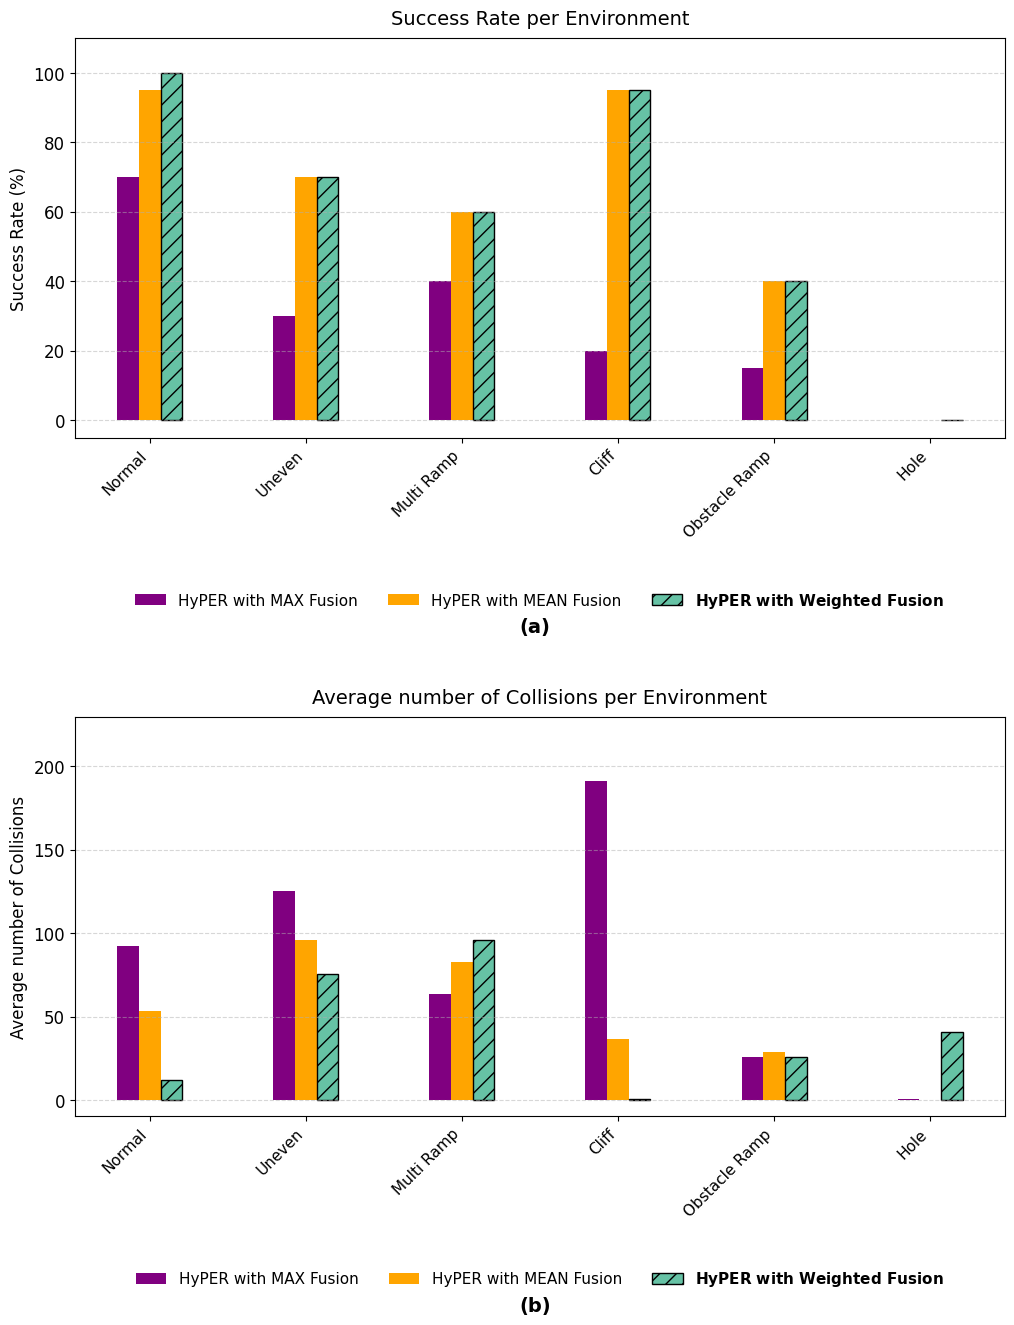

In [18]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

# 1. DEFINITIONS AND MAPPING
canonical_map = {
    # --- Coordinates ---
    ((-30, 7), (-22, 17)): "Normal",
    ((-30, -20), (-22, -6)): "Uneven",
    ((-31, -44), (-20, -37)): "Multi Ramp",
    ((-55, 5), (-41, 5)): "Cliff",
    ((-33, 40), (-20, 40)): "Ramp with Obs",
    ((-55, -13), (-41, -13)): "Hole",
    
    # --- Raw Strings ---
    "normal": "Normal",
    "uneven": "Uneven",
    "two_height_ramp": "Cliff",         # Maps old key to "Cliff"
    "ramp_obstacle": "Obstacle Ramp",   # Maps old key to "Obstacle Ramp"
    "mutlti ramp": "Multi Ramp",
    "multi ramp": "Multi Ramp",
    "hole": "Hole"
}

def relabel_stats(stats):
    new_stats = {}
    for key, values in stats.items():
        if key in canonical_map:
            label = canonical_map[key]
        elif str(key) in canonical_map:
            label = canonical_map[str(key)]
        else:
            label = str(key)
        new_stats[label] = values
    return new_stats

# 2. PROCESS DATA
# Run the relabeling FIRST
stats4_labeled = relabel_stats(stats4)
stats5_labeled = relabel_stats(stats5)
stats6_labeled = relabel_stats(stats6)

# 3. STRICT ORDER DEFINITION (FIXED)
# IMPORTANT: These must match the VALUES in canonical_map, not the keys.
desired_order = ["Normal", "Uneven", "Multi Ramp", "Cliff", "Obstacle Ramp", "Hole"]

# 4. BUILD LABEL SET
label_set = (
    set(stats4_labeled.keys())
    .union(stats5_labeled.keys())
    .union(stats6_labeled.keys())
)

# 5. SORT LABELS
# Filter desired_order to only include labels that actually exist in the data
all_labels = [lbl for lbl in desired_order if lbl in label_set]
# Add any unexpected labels found in the data to the end
leftovers = sorted(list(label_set - set(all_labels)))
all_labels.extend(leftovers)

# 6. DISPLAY LABELS
# Since relabel_stats already cleaned the names, we can use all_labels directly
# or apply simple title casing if needed.
display_labels = all_labels 

# ────────────────────────────────────────────────
# Data Extraction
# ────────────────────────────────────────────────
full_rates = [stats4_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]
test_rates = [stats5_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]
new_rates  = [stats6_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]

full_cols  = [stats4_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]
test_cols  = [stats5_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]
new_cols   = [stats6_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]

# ────────────────────────────────────────────────
# LAYOUT SETUP
# ────────────────────────────────────────────────
group_spacing = 1.8
x = np.arange(len(all_labels)) * group_spacing
width = 0.25

offsets = [-1.0 * width, 0.0 * width, 1.0 * width]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(max(12, len(all_labels)*1.0), 14))
plt.subplots_adjust(hspace=0.7)

# ==========================================
# SUBPLOT 1: SUCCESS RATE
# ==========================================
ax1.bar(x + offsets[0], full_rates, width, label='HyPER with MAX Fusion',  color='purple')
ax1.bar(x + offsets[1], test_rates, width, label='HyPER with MEAN Fusion', color='orange')
ax1.bar(x + offsets[2], new_rates,  width, label=r'$\bf{HyPER\ with\ Weighted\ Fusion}$ ', 
        color='#66C2A5', edgecolor='black', hatch='//')

ax1.set_xticks(x)
ax1.set_xticklabels(display_labels, rotation=45, ha='right', fontsize=11)
ax1.set_ylabel("Success Rate (%)", fontsize=12)
ax1.set_title("Success Rate per Environment", fontsize=14, pad=10)

ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=3, frameon=False, fontsize=11)
ax1.text(0.495, -0.45, "(a)", transform=ax1.transAxes, ha='center', va='top', fontsize=14, fontweight='bold')

ax1.set_ylim(-5, 110)
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)

# ==========================================
# SUBPLOT 2: COLLISIONS
# ==========================================
ax2.bar(x + offsets[0], full_cols, width, label='HyPER with MAX Fusion',  color='purple')
ax2.bar(x + offsets[1], test_cols, width, label='HyPER with MEAN Fusion', color='orange')
ax2.bar(x + offsets[2], new_cols,  width, label=r'$\bf{HyPER\ with\ Weighted\ Fusion}$', 
        color='#66C2A5', edgecolor='black', hatch='//')

ax2.set_xticks(x)
ax2.set_xticklabels(display_labels, rotation=45, ha='right', fontsize=11)
ax2.set_ylabel("Average number of Collisions", fontsize=12)
ax2.set_title("Average number of Collisions per Environment", fontsize=14, pad=10)

ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=3, frameon=False, fontsize=11)
ax2.text(0.495, -0.45, "(b)", transform=ax2.transAxes, ha='center', va='top', fontsize=14, fontweight='bold')

max_col_val = max(max(full_cols), max(test_cols), max(new_cols))
ax2.set_ylim(-max_col_val*0.05, max_col_val * 1.2)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.savefig("fusion_comparison.pdf", format="pdf", bbox_inches='tight')
plt.show()

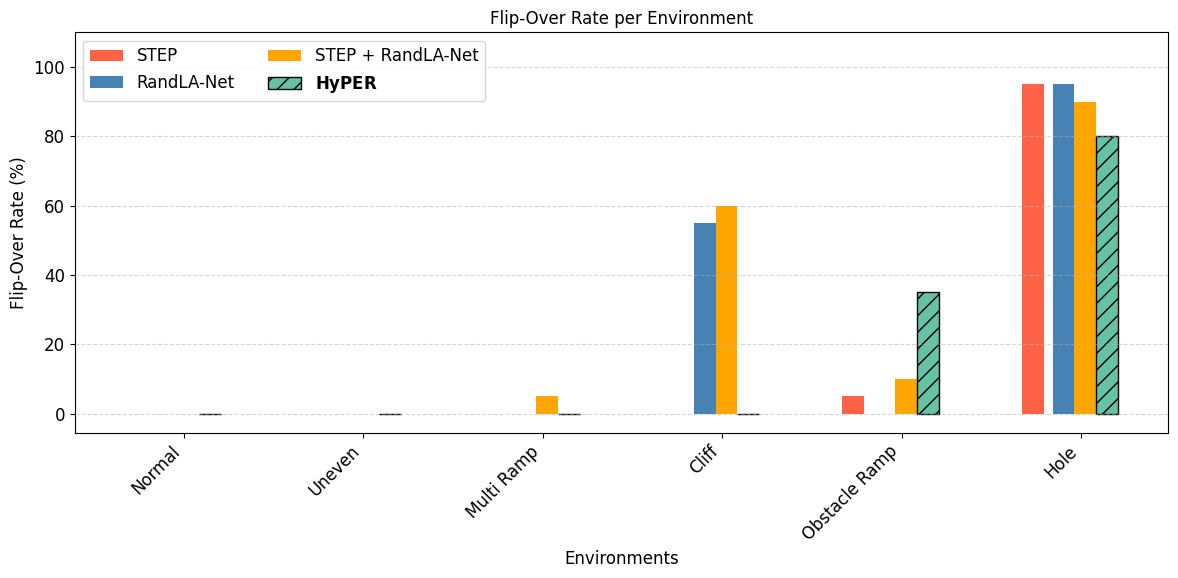

--- Flip-Over Rate (%) ---
  Environment  STEP  RandLA-Net  STEP + RandLA-Net  HyPER
       Normal   0.0         0.0                0.0    0.0
       Uneven   0.0         0.0                0.0    0.0
   Multi Ramp   0.0         0.0                5.0    0.0
        Cliff   0.0        55.0               60.0    0.0
Obstacle Ramp   5.0         0.0               10.0   35.0
         Hole  95.0        95.0               90.0   80.0


In [19]:
stats1_labeled = relabel_stats(stats1)
stats2_labeled = relabel_stats(stats2)
stats3_labeled = relabel_stats(stats3)
stats4_labeled = relabel_stats(stats4)
stats5_labeled = relabel_stats(stats5)
stats6_labeled = relabel_stats(stats6)  # <-- NEW

# Combine all labels with custom order (ensure 'normal' first per settings)
label_set = (
    set(stats1_labeled.keys())
    .union(stats2_labeled.keys())
    .union(stats3_labeled.keys())
    .union(stats4_labeled.keys())
    .union(stats5_labeled.keys())
    .union(stats6_labeled.keys())
)
all_labels = [lbl for lbl in desired_order if lbl in label_set] + sorted(label_set - set(desired_order))
# Build flip-over series
step_flip    = [stats1_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]
randla_flip  = [stats2_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]
combine_flip = [stats3_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]
full_flip    = [stats4_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]
test_flip    = [stats5_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]
new_flip     = [stats6_labeled.get(label, {}).get("flip_over_rate", 0) for label in all_labels]

# Plotting
group_spacing = 1.8
x = np.arange(len(all_labels)) * group_spacing

width = 0.22  # Bar width

offsets = [
    -2.2 * width,  # STEP: Positioned further left
    -0.8 * width,  # RandLA: Start of the right group
     0.2 * width,  # Combine: Middle of the right group
     1.2 * width   # AWARE: End of the right group
]

plt.figure(figsize=(max(12, len(all_labels)*0.8), 6))

plt.bar(x + offsets[0], step_flip,    width, label='STEP', color='tomato')
plt.bar(x + offsets[1], randla_flip,  width, label='RandLA-Net', color='steelblue')
plt.bar(x + offsets[2], combine_flip, width, label='STEP + RandLA-Net', color='orange')

plt.bar(
    x + offsets[3],
    new_flip,
    width,
    label=r'$\bf{HyPER}$',
    color='#66C2A5',
    edgecolor='black',
    hatch='//'
)

plt.xticks(x, all_labels, rotation=45, ha='right')
plt.xlabel("Environments")
plt.ylabel("Flip-Over Rate (%)")
ylim_val = 110
plt.ylim(-ylim_val*0.05, ylim_val)
plt.title("Flip-Over Rate per Environment")
plt.legend(ncol=2)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
data = {
    "Environment": all_labels,
    "STEP": step_flip,
    "RandLA-Net": randla_flip,
    "STEP + RandLA-Net": combine_flip,
    "HyPER": new_flip
}

# 2. Convert to a Pandas DataFrame
df = pd.DataFrame(data)

# --- OPTION A: Print clear text table for viewing ---
print("--- Flip-Over Rate (%) ---")
print(df.to_string(index=False))

# --- OPTION B: Save as CSV ---
df.to_csv("flip_over_rates.csv", index=False)


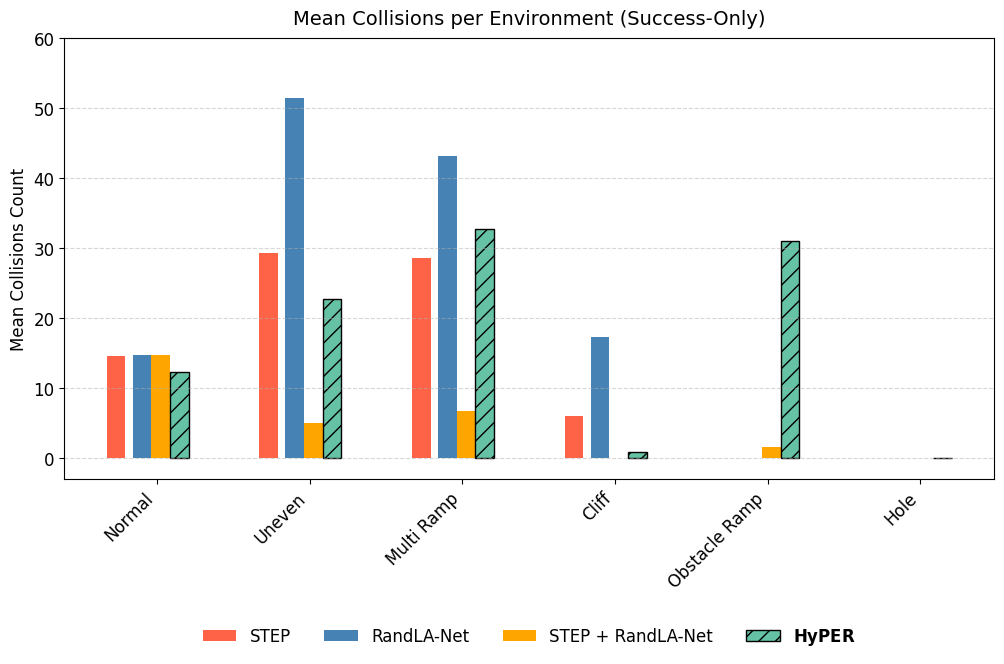

In [20]:
stats1_labeled = relabel_stats(stats1)
stats2_labeled = relabel_stats(stats2)
stats3_labeled = relabel_stats(stats3)
stats4_labeled = relabel_stats(stats4)
stats5_labeled = relabel_stats(stats5)
stats6_labeled = relabel_stats(stats6)  # <-- NEW

# 1. SETUP LABELS (Ensure 'Hole' is last)
label_set = (
    set(stats1_labeled.keys())
    .union(stats2_labeled.keys())
    .union(stats3_labeled.keys())
    .union(stats4_labeled.keys())
    .union(stats5_labeled.keys())
    .union(stats6_labeled.keys())
)

# Initial sort based on desired_order
all_labels = [lbl for lbl in desired_order if lbl in label_set] + sorted(label_set - set(desired_order))

# FORCE 'HOLE' TO BE LAST
if 'Hole' in all_labels:
    all_labels.remove('Hole')
    all_labels.append('Hole')

# Build arrays from mean_collision_success
step_means    = [stats1_labeled.get(label, {}).get("mean_collision_success", 0) for label in all_labels]
randla_means  = [stats2_labeled.get(label, {}).get("mean_collision_success", 0) for label in all_labels]
combine_means = [stats3_labeled.get(label, {}).get("mean_collision_success", 0) for label in all_labels]
new_means     = [stats6_labeled.get(label, {}).get("mean_collision_success", 0) for label in all_labels]

# Spacing + centered offsets
group_spacing = 1.8
x = np.arange(len(all_labels)) * group_spacing

width = 0.22  # Bar width

offsets = [
    -2.2 * width,  # STEP
    -0.8 * width,  # RandLA
     0.2 * width,  # Combine
     1.2 * width   # HyPER
]

plt.figure(figsize=(max(12, len(all_labels)*0.8), 7)) # Increased height slightly for bottom legend

bars1 = plt.bar(x + offsets[0], step_means,    width, label='STEP',              color='tomato')
bars2 = plt.bar(x + offsets[1], randla_means,  width, label='RandLA-Net',        color='steelblue')
bars3 = plt.bar(x + offsets[2], combine_means, width, label='STEP + RandLA-Net', color='orange')
bars6 = plt.bar(x + offsets[3], new_means,     width, label=r'$\bf{HyPER}$',     color='#66C2A5',
                edgecolor='black', hatch='//')

plt.xticks(x, all_labels, rotation=45, ha='right')
plt.ylabel("Mean Collisions Count")
plt.title("Mean Collisions per Environment (Success-Only)", fontsize=14, pad=10)

# Removed plt.xlabel("Environments") as requested

plt.grid(True, axis='y', linestyle='--', alpha=0.5)

# Fixed y-limit
ylim_val = 60
plt.ylim(-ylim_val*0.05, ylim_val)

# LEGEND BELOW GRAPH
# bbox_to_anchor=(x, y). y < 0 places it below the axis.
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4, frameon=False, fontsize=12)

# Adjust bottom margin to accommodate the external legend
plt.subplots_adjust(bottom=0.25)

plt.show()

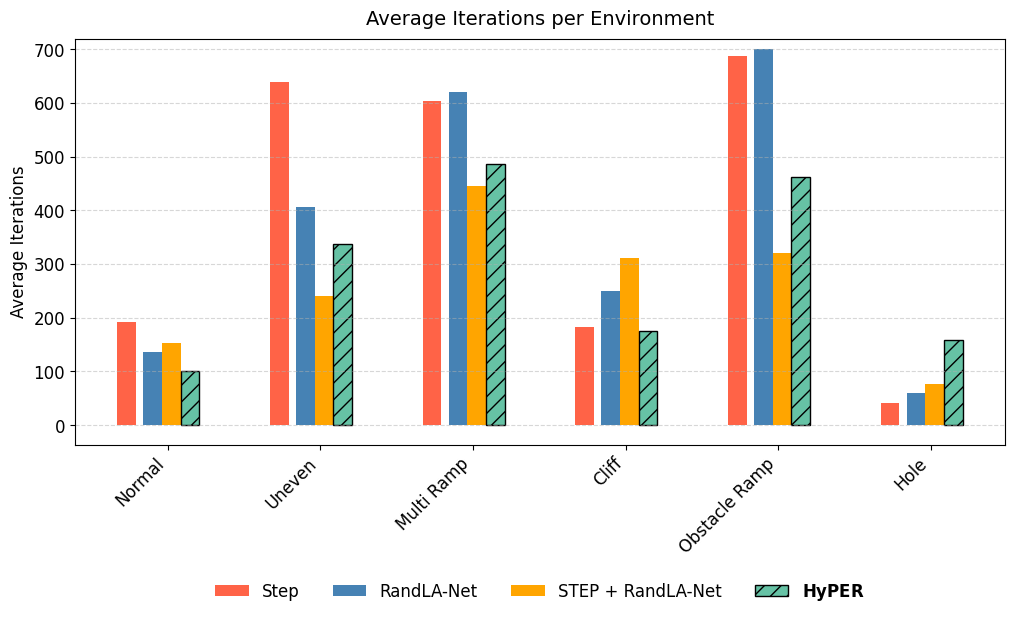

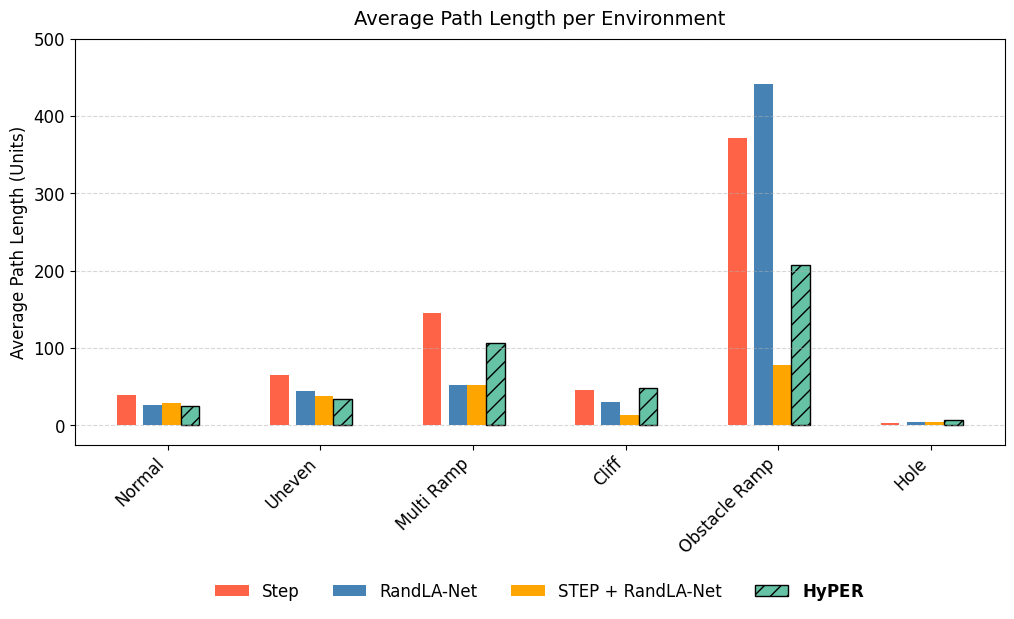

In [21]:
stats1_labeled = relabel_stats(stats1)
stats2_labeled = relabel_stats(stats2)
stats3_labeled = relabel_stats(stats3)
stats4_labeled = relabel_stats(stats4)
stats5_labeled = relabel_stats(stats5)
stats6_labeled = relabel_stats(stats6)  # <-- NEW

# Combine all labels with custom order (ensure 'normal' first per settings)
label_set = (
    set(stats1_labeled.keys())
    .union(stats2_labeled.keys())
    .union(stats3_labeled.keys())
    .union(stats4_labeled.keys())
    .union(stats5_labeled.keys())
    .union(stats6_labeled.keys())
)

# Sort labels based on desired_order
all_labels = [lbl for lbl in desired_order if lbl in label_set] + sorted(label_set - set(desired_order))

# FORCE 'Hole' TO BE LAST
if 'Hole' in all_labels:
    all_labels.remove('Hole')
    all_labels.append('Hole')

# Extract Data
step_counts     = [stats1_labeled.get(label, {}).get("count", 0) for label in all_labels]
randla_counts   = [stats2_labeled.get(label, {}).get("count", 0) for label in all_labels]
combine_counts  = [stats3_labeled.get(label, {}).get("count", 0) for label in all_labels]
new_counts      = [stats6_labeled.get(label, {}).get("count", 0) for label in all_labels]

step_lengths    = [stats1_labeled.get(label, {}).get("total_length", 0) for label in all_labels]
randla_lengths  = [stats2_labeled.get(label, {}).get("total_length", 0) for label in all_labels]
combine_lengths = [stats3_labeled.get(label, {}).get("total_length", 0) for label in all_labels]
new_lengths     = [stats6_labeled.get(label, {}).get("total_length", 0) for label in all_labels]

# Layout Settings
group_spacing = 1.8
x = np.arange(len(all_labels)) * group_spacing
width = 0.22 

offsets = [
    -2.2 * width,  # STEP
    -0.8 * width,  # RandLA
     0.2 * width,  # Combine
     1.2 * width   # HyPER
]

# ==========================================
# FIGURE 1: MEAN COUNTS (a)
# ==========================================
fig1 = plt.figure(figsize=(max(12, len(all_labels)*0.8), 7))
ax1 = plt.gca()

ax1.bar(x + offsets[0], step_counts,    width, label='Step',              color='tomato')
ax1.bar(x + offsets[1], randla_counts,  width, label='RandLA-Net',        color='steelblue')
ax1.bar(x + offsets[2], combine_counts, width, label='STEP + RandLA-Net', color='orange')
ax1.bar(x + offsets[3], new_counts,     width, label=r'$\bf{HyPER}$',     color='#66C2A5', 
        edgecolor='black', hatch='//')

ax1.set_xticks(x)
ax1.set_xticklabels(all_labels, rotation=45, ha='right')
ax1.set_ylabel("Average Iterations")
ax1.set_title("Average Iterations per Environment", fontsize=14, pad=10)

ax1.grid(True, axis='y', linestyle='--', alpha=0.5)
ax1.set_ylim(-720*0.05, 720) 

# Legend Below
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4, frameon=False, fontsize=12)

# Label (a) Below Legend
# ax1.text(0.5, -0.28, "(a)", transform=ax1.transAxes, 
#          ha='center', va='top', fontsize=14, fontweight='bold', color='black')

plt.subplots_adjust(bottom=0.3)
plt.savefig("TotalCount_NCompare.pdf", format="pdf", bbox_inches='tight')
plt.show()

# ==========================================
# FIGURE 2: MEAN TOTAL DISTANCE (b)
# ==========================================
fig2 = plt.figure(figsize=(max(12, len(all_labels)*0.8), 7))
ax2 = plt.gca()

ax2.bar(x + offsets[0], step_lengths,    width, label='Step',              color='tomato')
ax2.bar(x + offsets[1], randla_lengths,  width, label='RandLA-Net',        color='steelblue')
ax2.bar(x + offsets[2], combine_lengths, width, label='STEP + RandLA-Net', color='orange')
ax2.bar(x + offsets[3], new_lengths,     width, label=r'$\bf{HyPER}$',     color='#66C2A5',
        edgecolor='black', hatch='//')

ax2.set_xticks(x)
ax2.set_xticklabels(all_labels, rotation=45, ha='right')
ax2.set_ylabel("Average Path Length (Units)")
ax2.set_title("Average Path Length per Environment", fontsize=14, pad=10)

ax2.grid(True, axis='y', linestyle='--', alpha=0.5)
ax2.set_ylim(-500*0.05, 500)

# Legend Below
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4, frameon=False, fontsize=12)

# Label (b) Below Legend
# ax2.text(0.5, -0.28, "(b)", transform=ax2.transAxes, 
#          ha='center', va='top', fontsize=14, fontweight='bold', color='black')

plt.subplots_adjust(bottom=0.3)
plt.savefig("TotalDist_NCompare.pdf", format="pdf", bbox_inches='tight')
plt.show()

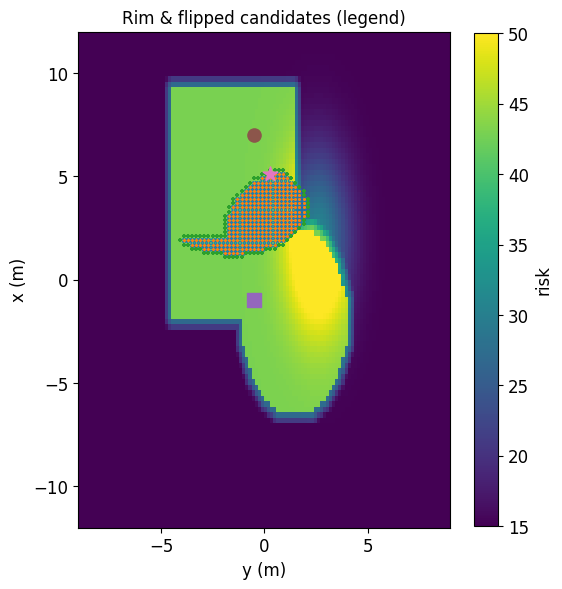

('/mnt/data/rim_debug_legend.png', {'chosen_ij': None, 'num_candidates': 0})

In [22]:
# Re-run the rim visualization with legend (after reset)
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label as _label, binary_dilation as _bd, generate_binary_structure as _gbs, distance_transform_edt as _dt
from scipy.ndimage import distance_transform_edt as edt

def compute_and_visualize_rim_debug_with_legend(
    risk_grid, x_edges, y_edges,
    vehicle_xy, destination_point, gi, gj, MAX,
    save_path=None
):
    safe_thr = 0.95 * MAX
    struct = _gbs(2, 1)
    high_mask = np.isfinite(risk_grid) & (risk_grid >= safe_thr)

    if not high_mask[gi, gj]:
        hi, hj = np.nonzero(high_mask)
        if hi.size > 0:
            Xc = (x_edges[:-1] + x_edges[1:]) * 0.5
            Yc = (y_edges[:-1] + y_edges[1:]) * 0.5
            centers = np.column_stack((Xc[hi], Yc[hj]))
            gxy = np.asarray(destination_point, dtype=float)
            best = np.argmin(np.linalg.norm(centers - gxy, axis=1))
            gi, gj = int(hi[best]), int(hj[best])

    labeled, ncc = _label(high_mask, structure=struct)
    comp_id = labeled[gi, gj] if ncc > 0 and labeled[gi, gj] != 0 else 0

    if comp_id != 0:
        comp_mask = (labeled == comp_id)
    else:
        comp_mask = np.zeros_like(high_mask, dtype=bool)
        comp_mask[gi, gj] = True

    rim = _bd(comp_mask, structure=struct) & (~comp_mask)

    gxy = np.asarray(destination_point, dtype=float)
    vxy = np.asarray(vehicle_xy, dtype=float)
    g_to_v = vxy - gxy
    g_to_v /= (np.linalg.norm(g_to_v) + 1e-9)

    Xc = (x_edges[:-1] + x_edges[1:]) * 0.5
    Yc = (y_edges[:-1] + y_edges[1:]) * 0.5
    ii, jj = np.indices(risk_grid.shape)
    centers = np.column_stack((Xc[ii.ravel()], Yc[jj.ravel()]))
    dirs = centers - gxy
    dirs /= (np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-9)
    dots = (dirs @ g_to_v).reshape(risk_grid.shape)
    flipped_mask = (dots <= 0.0)

    cand_mask = rim & np.isfinite(risk_grid) & (risk_grid < safe_thr) & flipped_mask
    cand_cells = np.argwhere(cand_mask)
    if cand_cells.size == 0:
        rim2 = _bd(rim, structure=struct) & (~comp_mask)
        cand_mask = rim2 & np.isfinite(risk_grid) & (risk_grid < safe_thr) & flipped_mask
        cand_cells = np.argwhere(cand_mask)

    chosen_ij = None
    if cand_cells.size > 0:
        dist_from_blob = _dt(~comp_mask)
        scores = dist_from_blob[cand_cells[:, 0], cand_cells[:, 1]]
        risks = risk_grid[cand_cells[:, 0], cand_cells[:, 1]]
        order = np.lexsort((risks, -scores))
        best = cand_cells[order[0]]
        chosen_ij = (int(best[0]), int(best[1]))

    fig, ax = plt.subplots(figsize=(6,8))
    extent = [y_edges[0], y_edges[-1], x_edges[0], x_edges[-1]]
    im = ax.imshow(np.flipud(risk_grid.T), extent=extent, origin="lower", aspect="equal")
    fig.colorbar(im, ax=ax, shrink=0.8, label="risk")

    hi, hj = np.nonzero(high_mask)
    ax.scatter(Yc[hj], Xc[hi], s=8, marker='x', label='High-risk (≥0.95·MAX)')
    ci, cj = np.nonzero(comp_mask)
    ax.scatter(Yc[cj], Xc[ci], s=6, marker='.', label='Blocking component')
    ri, rj = np.nonzero(rim)
    ax.scatter(Yc[rj], Xc[ri], s=8, marker='+', label='1-cell rim')
    fi, fj = np.nonzero(cand_mask)
    # TOP  
    ax.scatter(Yc[fj], Xc[fi], s=34, marker='+', alpha=0.8, label='Candidates (safe & flipped)')
    if chosen_ij is not None:
        ax.scatter([Yc[chosen_ij[1]]], [Xc[chosen_ij[0]]], marker='^', s=120, label='Chosen candidate')
    ax.scatter([vehicle_xy[1]], [vehicle_xy[0]], marker='s', s=90, label='Vehicle')
    ax.scatter([destination_point[1]], [destination_point[0]], marker='o', s=90, label='Final goal')
    ax.scatter([Yc[gj]], [Xc[gi]], marker='*', s=120, label='Start (gi,gj)')

    # ax.legend(loc='upper right', fontsize=8)
    ax.set_title("Rim & flipped candidates (legend)")
    ax.set_xlabel("y (m)")
    ax.set_ylabel("x (m)")

    # if save_path:
    #     fig.savefig(save_path, bbox_inches="tight", dpi=140)
    plt.show()

    return {"chosen_ij": chosen_ij, "num_candidates": int(cand_cells.shape[0])}

# --- Synthetic map ---
Nx, Ny = 120, 90
x_edges = np.linspace(-12, 12, Nx+1)
y_edges = np.linspace(-9, 9, Ny+1)
Xc = (x_edges[:-1] + x_edges[1:]) * 0.5
Yc = (y_edges[:-1] + y_edges[1:]) * 0.5
X, Y = np.meshgrid(Xc, Yc, indexing="ij")

MAX = 50.0
risk = 15.0 * np.ones_like(X)
rect = (X > -6.0) & (X < 2.0) & (Y > -7.0) & (Y < 1.5)
cap = (((X-2.0)**2 + (Y-1.5)**2) < (3.4**2)) & (Y >= 1.5-3.4)
obstacle = rect | cap
dist_out = edt(~obstacle)
risk += 6.0*np.clip(3.0 - dist_out, 0, None)
risk += 10.0*np.clip(1.0 - dist_out, 0, None)
risk += 16.0*np.exp(-((X-3.5)**2/(2*1.4**2) + (Y+1.5)**2/(2*2.2**2)))
risk = np.clip(risk, 0, MAX)

vehicle_xy = (-1.0, -0.5)
destination_point = (7.0, -0.5)
gi = np.searchsorted(Xc, 6.0); gi = int(np.clip(gi, 0, Nx-1))
gj = np.searchsorted(Yc, -0.5); gj = int(np.clip(gj, 0, Ny-1))

out_path = "/mnt/data/rim_debug_legend.png"
res = compute_and_visualize_rim_debug_with_legend(
    risk_grid=risk, x_edges=x_edges, y_edges=y_edges,
    vehicle_xy=vehicle_xy, destination_point=destination_point,
    gi=gi, gj=gj, MAX=MAX, save_path=out_path
)
out_path, res


In [23]:
from collections import defaultdict
import json
import math

# Load data
with open('finalstep_stats_3.json') as f:
    data = json.load(f)
with open('finalstepmean_stats_3.json') as f2:
    data2 = json.load(f2)
with open('finalstepnoseg_stats_3.json') as f3:
    data3 = json.load(f3)
with open('finalmax_stats_3.json') as f4:
    data4 = json.load(f4)
with open('finalmean_stats_3.json') as f5:
    data5 = json.load(f5)
with open('finalcombine_stats_3.json') as f6:
    data6 = json.load(f6)


def euclidean(p1, p2):
    """Simple 2D Euclidean distance"""
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)


# -------------------------------------------------
# Environment mapping + snapping
# -------------------------------------------------
env_map = {
    ((-30, 7), (-22, 17)): "normal",
    ((-30, -20), (-22, -6)): "uneven",
    ((-31, -44), (-20, -37)): "mutlti ramp",
    ((-55, 5), (-41, 5)): "two_height_ramp",
    ((-33, 40), (-20, 40)): "ramp_obstacle",
    ((-55, -13), (-41, -13)): "hole",
}


def get_env_name(start_point, goal_point, max_snap_dist=5.0):
    """
    Map (start, goal) to the closest known environment in env_map.
    """
    # 1) Exact rounded lookup (backwards compatible)
    start_rounded = tuple(round(x) for x in start_point)
    goal_rounded = tuple(round(x) for x in goal_point)
    key = (start_rounded, goal_rounded)

    if key in env_map:
        return env_map[key]

    # 2) Find closest template pair in env_map
    best_name = None
    best_dist = float("inf")

    for (tmpl_start, tmpl_goal), name in env_map.items():
        dist = euclidean(start_point, tmpl_start) + euclidean(goal_point, tmpl_goal)
        if dist < best_dist:
            best_dist = dist
            best_name = name

    # 3) Snap if close enough
    if best_dist <= max_snap_dist:
        return best_name

    # Fallback: keep explicit mapping
    return f"{start_rounded}→{goal_rounded}"


# -------------------------------------------------
# Processing (now grouped by environment name)
# -------------------------------------------------
def process_data(data):
    groups = defaultdict(list)

    for entry in data:
        env_key = get_env_name(entry["start_point"], entry["goal_point"])
        groups[env_key].append(entry)

    stats = {}
    for key, group in groups.items():
        total_lengths = [sum(entry["total_length"]) for entry in group]
        dist_togoals = [entry["dist_to_goal"] for entry in group]
        collision_counts = [entry["collision_count"] for entry in group]
        counts = [entry["count"] for entry in group]
        reach_goals = [entry["reach_goal"] for entry in group]

        # Distances involving current_pos
        dist_start_curr = [
            euclidean(entry["start_point"], entry["current_pos"]) for entry in group
        ]
        dist_curr_goal = [
            euclidean(entry["current_pos"], entry["goal_point"]) for entry in group
        ]

        mean_total_length = sum(total_lengths) / len(total_lengths)
        mean_dist_togoal = sum(dist_togoals) / len(dist_togoals)
        mean_collision = sum(collision_counts) / len(collision_counts)
        mean_count = sum(counts) / len(counts)
        reach_goal_rate = sum(reach_goals) / len(reach_goals)

        mean_start_curr = sum(dist_start_curr) / len(dist_start_curr)
        mean_curr_goal = sum(dist_curr_goal) / len(dist_curr_goal)

        success_collision_counts = [
            entry["collision_count"] for entry in group if entry.get("reach_goal")
        ]
        mean_collision_success = (
            sum(success_collision_counts) / len(success_collision_counts)
            if success_collision_counts else 0.0
        )

        # ---------------------------------------------
        # Flip-over metric:
        #   reach_goal == False AND count != 700
        # ---------------------------------------------
        flip_over_flags = [
            (not entry["reach_goal"]) and (entry["count"] != 700)
            for entry in group
        ]
        flip_over_count = sum(flip_over_flags)          # e.g. 3 (out of 20)
        flip_over_rate = flip_over_count / len(group) * 100.0  # percent, like (3/20)*100

        stats[key] = {
            "total_length": mean_total_length,
            "dist_togoal": mean_dist_togoal,
            "collision_count": mean_collision,
            "count": mean_count,
            "reach_goal_rate": reach_goal_rate * 100,  # percent
            "dist_start_to_current": mean_start_curr,
            "dist_current_to_goal": mean_curr_goal,
            "mean_collision_success": mean_collision_success,
            "flip_over_count": flip_over_count,        # how many flips out of N (e.g. 3 of 20)
            "flip_over_rate": flip_over_rate,          # as percentage
        }
    return stats


# Process all datasets (stats now keyed by env name like 'hole', 'normal', etc.)
stats1 = process_data(data)
stats2 = process_data(data2)
stats3 = process_data(data3)
stats4 = process_data(data4)
stats5 = process_data(data5)
stats6 = process_data(data6)


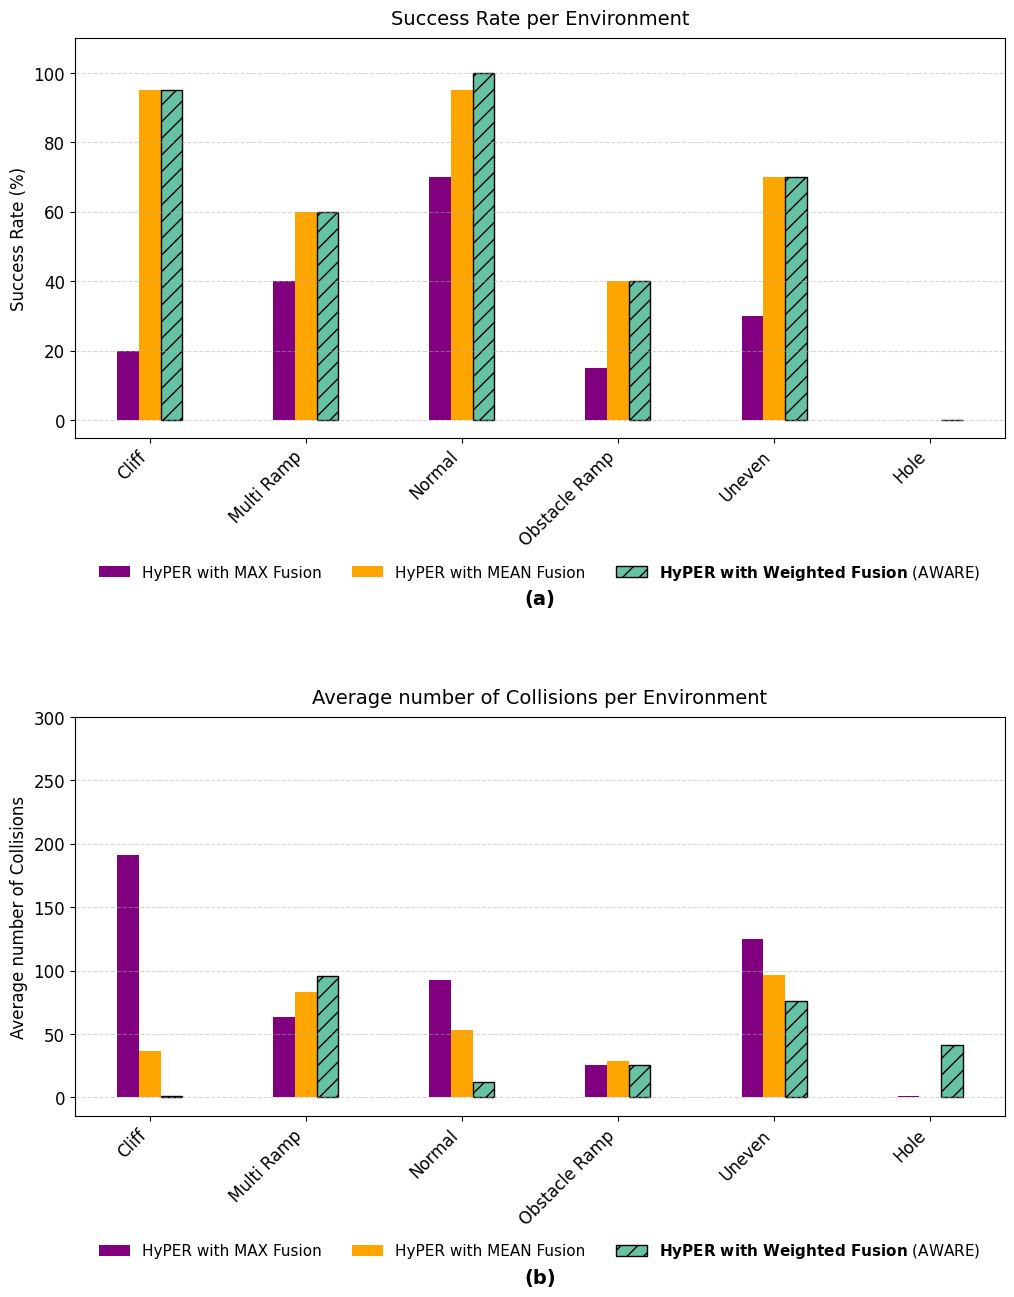

In [24]:
desired_order = ["normal", "uneven", "multi ramp", "two_height_ramp", "ramp_obstacle", "hole"]
label_set = (
    set(stats1_labeled.keys())
    .union(stats2_labeled.keys())
    .union(stats3_labeled.keys())
    .union(stats4_labeled.keys())
    .union(stats5_labeled.keys())
    .union(stats6_labeled.keys())
)

# Initial sort
all_labels = [lbl for lbl in desired_order if lbl in label_set] + sorted(label_set - set(desired_order))

# FORCE 'hole' TO BE LAST (case-insensitive check)
for variant in ['hole', 'Hole', 'HOLE']:
    if variant in all_labels:
        all_labels.remove(variant)
        all_labels.append(variant)
        break

# ────────────────────────────────────────────────
# Data Extraction
# ────────────────────────────────────────────────
# Success Rates
full_rates = [stats4_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]
test_rates = [stats5_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]
new_rates  = [stats6_labeled.get(l, {}).get("reach_goal_rate", 0) for l in all_labels]

# Collision Means
full_cols  = [stats4_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]
test_cols  = [stats5_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]
new_cols   = [stats6_labeled.get(l, {}).get("collision_count", 0) for l in all_labels]

# ────────────────────────────────────────────────
# LAYOUT SETUP
# ────────────────────────────────────────────────
group_spacing = 1.8
x = np.arange(len(all_labels)) * group_spacing
width = 0.25

# 3 Bars per group, so we center them
offsets = [
    -1.0 * width, # MAX
     0.0 * width, # MEAN
     1.0 * width  # Weighted
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(max(12, len(all_labels)*0.8), 14))
plt.subplots_adjust(hspace=0.7)

# ==========================================
# SUBPLOT 1: SUCCESS RATE (Top)
# ==========================================
ax1.bar(x + offsets[0], full_rates, width, label='HyPER with MAX Fusion',  color='purple')
ax1.bar(x + offsets[1], test_rates, width, label='HyPER with MEAN Fusion', color='orange')
ax1.bar(x + offsets[2], new_rates,  width, label=r'$\bf{HyPER\ with\ Weighted\ Fusion}$ (AWARE)', 
        color='#66C2A5', edgecolor='black', hatch='//')

ax1.set_xticks(x)
ax1.set_xticklabels(all_labels, rotation=45, ha='right')
ax1.set_ylabel("Success Rate (%)")
ax1.set_title("Success Rate per Environment", fontsize=14, pad=10)

ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=3, frameon=False, fontsize=11)
ax1.text(0.5, -0.38, "(a)", transform=ax1.transAxes, ha='center', va='top', fontsize=14, fontweight='bold')

ax1.set_ylim(-5, 110)
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)

# ==========================================
# SUBPLOT 2: MEAN COLLISIONS (Bottom)
# ==========================================
ax2.bar(x + offsets[0], full_cols, width, label='HyPER with MAX Fusion',  color='purple')
ax2.bar(x + offsets[1], test_cols, width, label='HyPER with MEAN Fusion', color='orange')
ax2.bar(x + offsets[2], new_cols,  width, label=r'$\bf{HyPER\ with\ Weighted\ Fusion}$ (AWARE)', 
        color='#66C2A5', edgecolor='black', hatch='//')

ax2.set_xticks(x)
ax2.set_xticklabels(all_labels, rotation=45, ha='right')
ax2.set_ylabel("Average number of Collisions")
ax2.set_title("Average number of Collisions per Environment", fontsize=14, pad=10)

ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=3, frameon=False, fontsize=11)
ax2.text(0.5, -0.38, "(b)", transform=ax2.transAxes, ha='center', va='top', fontsize=14, fontweight='bold')

ylim_val = 300
ax2.set_ylim(-ylim_val*0.05, ylim_val)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

# SAVING
plt.savefig("fusion_comparison.svg", format="svg", bbox_inches='tight')
plt.show()

In [25]:
# get the average colision

